# Colour Histograms and Back Projection

A **colour histogram** counts how often each colour value occurs in an image. It ignores where the colours are, so it describes what the image contains, not where. That makes it a simple feature: two images with the same colours have similar histograms even if the objects are placed differently.

Photo credit: <https://www.flickr.com/photos/jurvetson/7408464122>

This notebook does the following on a photo of a car's interior:
1. Computes a histogram for each colour channel, in BGR.
2. Computes histograms in **HSV**, which separates colour (hue), colour intensity (saturation) and brightness (value).
3. Builds a **hue-saturation** histogram, which describes a colour without its brightness.
4. Uses **back projection** to find where a sample colour occurs in the image.
5. Saves all results to `output/`.

## 1. Imports

- `cv2` (OpenCV): image I/O, histograms, colour conversion and back projection
- `matplotlib`: displaying images and plotting histograms
- `numpy`: array operations
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. Configuration

- `INPUT_PATH`: the photo. It is 4000 × 3000 pixels, so it is scaled down to `MAX_WIDTH` for the analysis.
- `SAMPLE_BOX`: the `(x1, y1, x2, y2)` box of the red car icon on the instrument cluster, in pixels of the scaled photo. The box is the sample colour for section 6.
- `BACKPROJECT_THRESHOLD`: the minimum back-projection value that counts as a match.
- `S_MIN`, `V_MIN`: the lowest saturation and brightness of a pixel that is used. Dark or grey pixels have a hue that is noise, so they are left out.
- All results are saved to `OUTPUT_DIR`.

In [2]:
INPUT_PATH = Path("tesla.jpg")
OUTPUT_DIR = Path("output")

MAX_WIDTH = 1000
SAMPLE_BOX = (244, 178, 258, 200)  # (x1, y1, x2, y2) inside the red car icon
BACKPROJECT_THRESHOLD = 50
S_MIN, V_MIN = 80, 40  # pixels with less saturation or brightness have an unreliable hue

## 3. Load the image and helper functions

Helper functions:
- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error.
- `show_images` shows several images side by side. Colour images are converted from BGR to RGB before display.
- `plot_channel_histograms` draws one histogram curve per channel, in the channel's colour.
- `save_image` writes an image and checks the result.

In [3]:
def load_image(path: Path) -> np.ndarray:
    """Load a colour image with OpenCV (BGR order) and raise a clear error if it fails."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

Original: 4000 x 3000; analysed at 1000 x 750


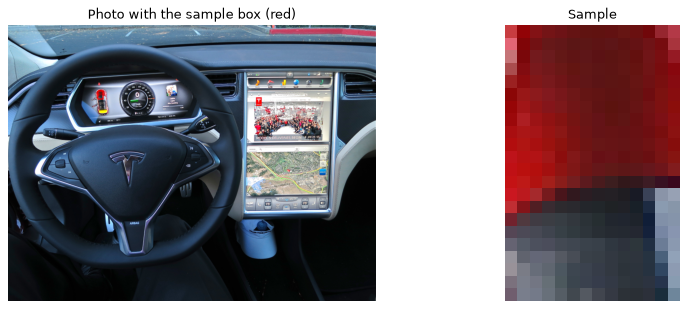

In [4]:
original = load_image(INPUT_PATH)
scale = MAX_WIDTH / original.shape[1]
photo = cv2.resize(original, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
print(f"Original: {original.shape[1]} x {original.shape[0]}; analysed at {photo.shape[1]} x {photo.shape[0]}")

x1, y1, x2, y2 = SAMPLE_BOX
sample = photo[y1:y2, x1:x2]
marked = photo.copy()
cv2.rectangle(marked, (x1, y1), (x2, y2), (0, 0, 255), 2)
show_images({"Photo with the sample box (red)": marked, "Sample": sample}, cols=2)

## 4. Histograms per BGR channel

`cv2.calcHist` counts the values of one channel, from 0 to 255, in 256 bins. The next cell computes this for each channel, and the curves are drawn in the colour of the channel.

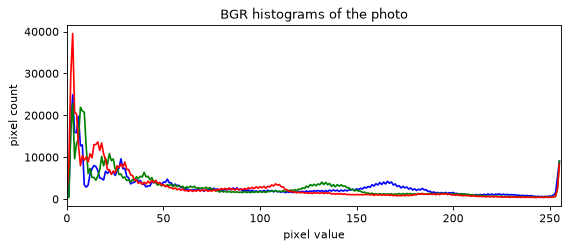

In [5]:
def plot_channel_histograms(img: np.ndarray, title: str) -> None:
    """One histogram curve per BGR channel, drawn in that channel's colour."""
    fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
    for i, colour in enumerate(("b", "g", "r")):
        hist = cv2.calcHist([img], [i], None, [256], [0, 256])
        ax.plot(hist, color=colour)
    ax.set_xlim([0, 256])
    ax.set_xlabel("pixel value")
    ax.set_ylabel("pixel count")
    ax.set_title(title)
    plt.show()


plot_channel_histograms(photo, "BGR histograms of the photo")

## 5. Histograms in HSV

HSV separates the colour from its brightness:
- **Hue** is the colour itself, on a circle from red through green and blue back to red. OpenCV stores hue in 0 to 179, half the usual 0 to 359 degrees, so it fits in one byte.
- **Saturation** is how strong the colour is. Grey and white have low saturation.
- **Value** is the brightness.

A colour in RGB changes all three channels when the light changes. In HSV it changes mainly in value, so the hue histogram is more stable under changes of lighting.

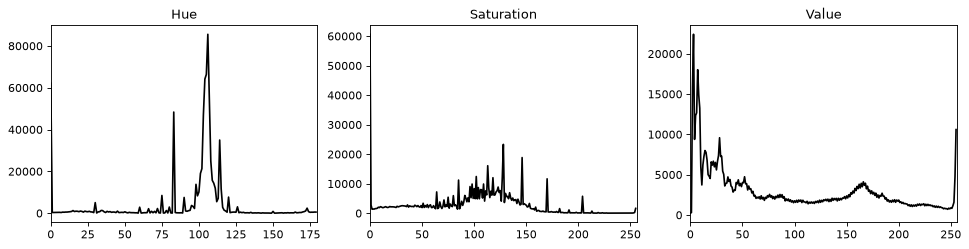

In [6]:
hsv = cv2.cvtColor(photo, cv2.COLOR_BGR2HSV)

fig, axes = plt.subplots(1, 3, figsize=(12, 3), layout="constrained")
for ax, (i, name, limit) in zip(axes, [(0, "Hue", 180), (1, "Saturation", 256), (2, "Value", 256)]):
    hist = cv2.calcHist([hsv], [i], None, [limit], [0, limit])
    ax.plot(hist, color="k")
    ax.set_title(name)
    ax.set_xlim([0, limit])
plt.show()

## 6. Hue-saturation histogram

Hue and saturation together describe a colour without its brightness. A two-dimensional histogram counts each pair (hue, saturation). It is shown below as an image, with hue along the horizontal axis and saturation along the vertical axis. Brighter cells are more frequent colour pairs.

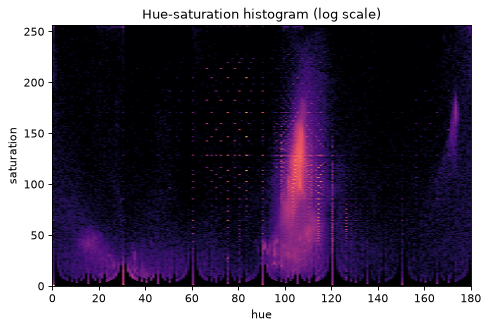

In [7]:
hs_hist = cv2.calcHist([hsv], [0, 1], None, [180, 256], [0, 180, 0, 256])

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.imshow(np.log1p(hs_hist.T), origin="lower", aspect="auto", cmap="magma", extent=[0, 180, 0, 256])
ax.set_xlabel("hue")
ax.set_ylabel("saturation")
ax.set_title("Hue-saturation histogram (log scale)")
plt.show()

## 7. Back projection: where does the sample colour occur?

**Back projection** takes the hue-saturation histogram of a sample, and gives each pixel of the photo the frequency of its colour in the sample. The result is an image of probabilities: bright where the colour of the sample is common, dark where it is rare.

The steps are:
1. Compute the hue-saturation histogram of the sample box. Pixels with low saturation or brightness are left out, because their hue is noise.
2. Normalise it so that the largest count is 255.
3. Back-project it onto the whole photo with `cv2.calcBackProject`.
4. Threshold the result, and keep only the pixels with a usable colour, to get a mask of the matching pixels.

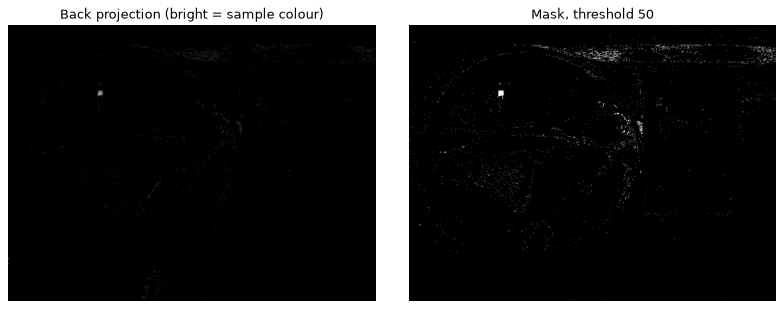

In [8]:
sample_hsv = cv2.cvtColor(sample, cv2.COLOR_BGR2HSV)
colour_ok = cv2.inRange(hsv, (0, S_MIN, V_MIN), (180, 255, 255))
sample_ok = cv2.inRange(sample_hsv, (0, S_MIN, V_MIN), (180, 255, 255))
sample_hist = cv2.calcHist([sample_hsv], [0, 1], sample_ok, [180, 256], [0, 180, 0, 256])
cv2.normalize(sample_hist, sample_hist, 0, 255, cv2.NORM_MINMAX)

back = cv2.calcBackProject([hsv], [0, 1], sample_hist, [0, 180, 0, 256], 1)
match_mask = np.where((back >= BACKPROJECT_THRESHOLD) & (colour_ok > 0), 255, 0).astype(np.uint8)

show_images({
    "Back projection (bright = sample colour)": back,
    f"Mask, threshold {BACKPROJECT_THRESHOLD}": match_mask,
}, cols=2)

## 8. Show the matching pixels

The mask is applied to the photo, so that only the pixels with the sample colour are kept. Pixels with a different colour turn black.

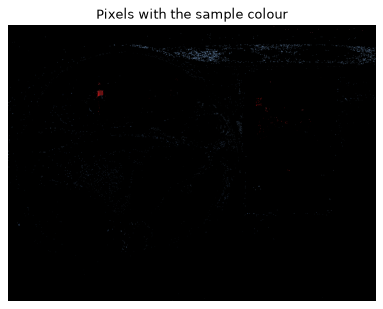

In [9]:
matches = cv2.bitwise_and(photo, photo, mask=match_mask)
show_images({"Pixels with the sample colour": matches})

## 9. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix.

In [10]:
stem = INPUT_PATH.stem
outputs = {
    "photo_scaled": photo,
    "back_projection": back,
    "match_mask": match_mask,
    "matches": matches,
}
for suffix, result in outputs.items():
    save_image(OUTPUT_DIR / f"{stem}_{suffix}.jpg", result)

Saved output/tesla_photo_scaled.jpg
Saved output/tesla_back_projection.jpg
Saved output/tesla_match_mask.jpg
Saved output/tesla_matches.jpg


## 10. Conclusion

- A **colour histogram** describes which colours an image contains, without their position. It is a simple, fast feature.
- **HSV** separates the colour from the brightness. The hue-saturation histogram is therefore more stable under lighting changes than the RGB histograms.
- **Back projection** turns a sample colour into a probability map over the image. A threshold turns it into a mask.
- Colour alone is not an object detector. Other objects can share the colour, and the mask has no notion of shape.

**Limits of this method**
- The colour depends on the light, the camera and the white balance, so a threshold tuned on one photo may fail on another.
- Colours that are rare in the sample are not found, and colours that are common in the scene are found everywhere.

**Current standards beyond this notebook**
- **Tracking:** CamShift and MeanShift use back projection of a colour histogram to follow an object from frame to frame. They are classical methods that are still used for simple tracking.
- **Learned features:** convolutional networks learn colour together with shape and texture, from labelled images. They are the standard for recognising objects in road scenes. I have not benchmarked them here.